# Assessment - 2

### Introduction
This project analyses ABC Company's employee dataset, consisting of 458 records and 9 columns, using Python. The objective is to understand employee distribution across teams and positions, analyse age groups and salary expenditure, and identify the relationship between age and salary.

Using Pandas, NumPy, Matplotlib, and Seaborn, the project involves data preprocessing, exploratory data analysis, and visualisation to identify key workforce trends and insights.

In [196]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [197]:
path = r"C:\Users\mneet\OneDrive\Desktop\Neethu's Learning\Entry App_ Advanced Program in DS\Wk_4\Assessment_2\ABC Company Dataset.csv"

In [198]:
df = pd.read_csv(path)

In [199]:
df

,Name,Team,Number,Position,Age,Height,Weight,College,Salary
0,Avery Bradley,Boston Celtics,0,PG,25,06-Feb,180,Texas,"7,730,337.00"
1,Jae Crowder,Boston Celtics,99,SF,25,06-Jun,235,Marquette,"6,796,117.00"
2,John Holland,Boston Celtics,30,SG,27,06-May,205,Boston University,NaN
3,R.J. Hunter,Boston Celtics,28,SG,22,06-May,185,Georgia State,"1,148,640.00"
4,Jonas Jerebko,Boston Celtics,8,PF,29,06-Oct,231,NaN,"5,000,000.00"
...,...,...,...,...,...,...,...,...,...
453,Shelvin Mack,Utah Jazz,8,PG,26,06-Mar,203,Butler,"2,433,333.00"
454,Raul Neto,Utah Jazz,25,PG,24,06-Jan,179,NaN,"900,000.00"
455,Tibor Pleiss,Utah Jazz,21,C,26,07-Mar,256,NaN,"2,900,000.00"
456,Jeff Withey,Utah Jazz,24,C,26,7-0,231,Kansas,"947,276.00"


In [200]:
# Structure and types
print(df.shape)
print(df.dtypes)

# Missing values
print("\nMissing values:")
print(df.isna().sum())

# Drop any duplicates
print("\nDuplicate Records:", df.duplicated().sum())

# Convert Salary into numeric format
df["Salary"] = pd.to_numeric(df["Salary"], errors="coerce")

# Calculate the mean salary (ignoring NaN values)
salary_mean = df["Salary"].mean()

# Replace missing Salary values with the mean
df["Salary"] = df["Salary"].fillna(salary_mean)

# Display mean salary
print("\nMean Salary:", round(salary_mean, 2))

# Check missing values after preprocessing
print("\nMissing Values After Preprocessing:")
print(df.isna().sum())

(458, 9)
Name         object
Team         object
Number        int64
Position     object
Age           int64
Height       object
Weight        int64
College      object
Salary      float64
dtype: object

Missing values:
Name         0
Team         0
Number       0
Position     0
Age          0
Height       0
Weight       0
College     84
Salary      11
dtype: int64

Duplicate Records: 0

Mean Salary: 4833969.55

Missing Values After Preprocessing:
Name         0
Team         0
Number       0
Position     0
Age          0
Height       0
Weight       0
College     84
Salary       0
dtype: int64


In [201]:
pd.options.display.float_format = '{:,.2f}'.format
df

,Name,Team,Number,Position,Age,Height,Weight,College,Salary
0,Avery Bradley,Boston Celtics,0,PG,25,06-Feb,180,Texas,"7,730,337.00"
1,Jae Crowder,Boston Celtics,99,SF,25,06-Jun,235,Marquette,"6,796,117.00"
2,John Holland,Boston Celtics,30,SG,27,06-May,205,Boston University,"4,833,969.55"
3,R.J. Hunter,Boston Celtics,28,SG,22,06-May,185,Georgia State,"1,148,640.00"
4,Jonas Jerebko,Boston Celtics,8,PF,29,06-Oct,231,NaN,"5,000,000.00"
...,...,...,...,...,...,...,...,...,...
453,Shelvin Mack,Utah Jazz,8,PG,26,06-Mar,203,Butler,"2,433,333.00"
454,Raul Neto,Utah Jazz,25,PG,24,06-Jan,179,NaN,"900,000.00"
455,Tibor Pleiss,Utah Jazz,21,C,26,07-Mar,256,NaN,"2,900,000.00"
456,Jeff Withey,Utah Jazz,24,C,26,7-0,231,Kansas,"947,276.00"



Correct the data in the "height" column by replacing it with random numbers between 150 and 180.


In [208]:
np.random.seed(42)
df["Height"] = np.random.randint(150,181,size=len(df))
print("\nUpdated Height:")
df["Height"]


Updated Height:


0      156
1      169
2      178
3      164
4      160
      ... 
453    168
454    153
455    152
456    166
457    166
Name: Height, Length: 458, dtype: int32

### Analysis Tasks:
 1. Determine the distribution of employees across each team and calculate the percentage split relative to the total number of employees. 


Employee Distribution across each team:
                        No. of Employees  Percentage (%)
Team                                                    
Atlanta Hawks                         15            3.28
Boston Celtics                        15            3.28
Brooklyn Nets                         15            3.28
Charlotte Hornets                     15            3.28
Chicago Bulls                         15            3.28
Cleveland Cavaliers                   15            3.28
Dallas Mavericks                      15            3.28
Denver Nuggets                        15            3.28
Detroit Pistons                       15            3.28
Golden State Warriors                 15            3.28
Houston Rockets                       15            3.28
Indiana Pacers                        15            3.28
Los Angeles Clippers                  15            3.28
Los Angeles Lakers                    15            3.28
Memphis Grizzlies                     18       

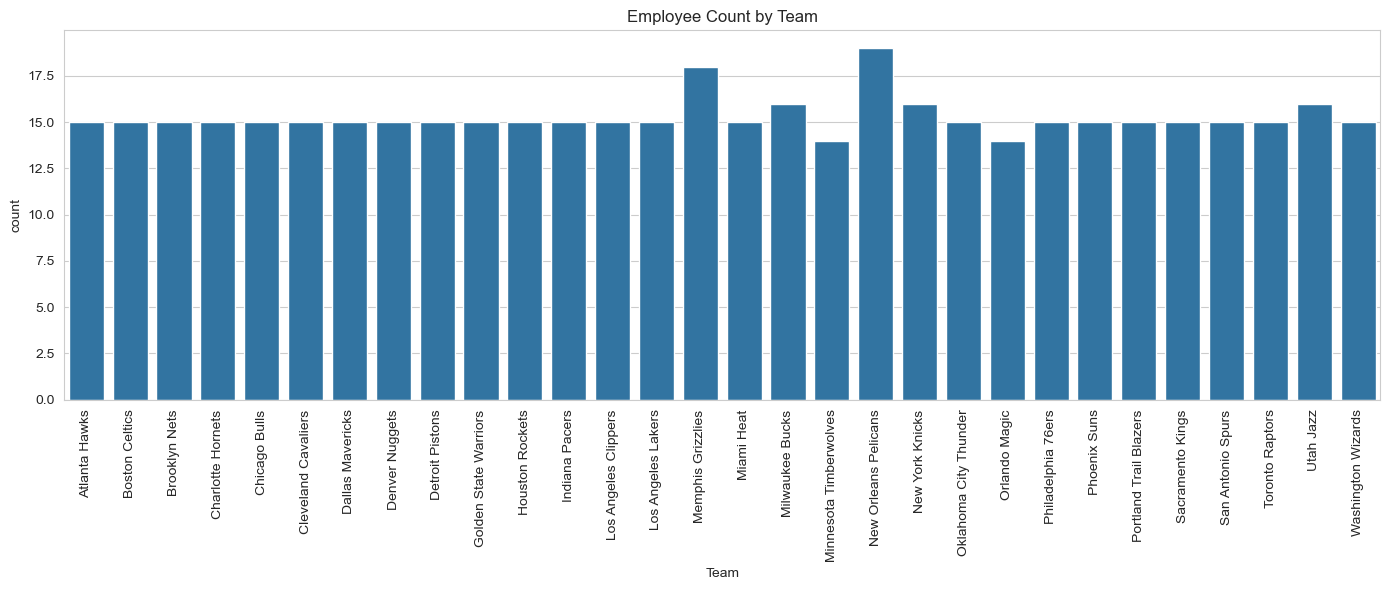

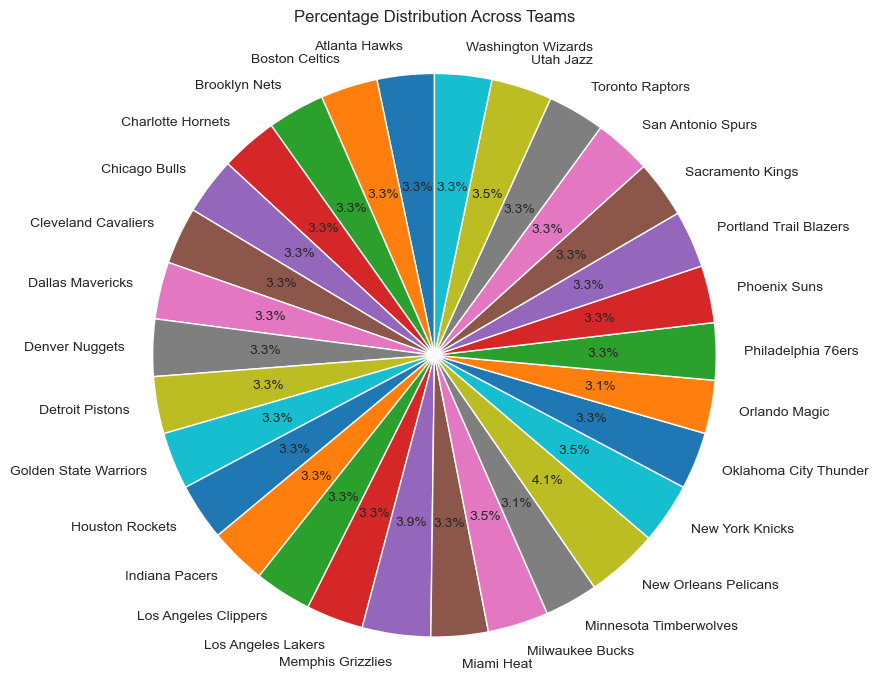

In [203]:
# Employee distribution across teams
team_counts = df.groupby('Team').size()

# Calculate percentage distribution
team_pct = (team_counts/df["Team"].count()*100).round(2)

# Combine results
team_distrubution = pd.DataFrame({
    "No. of Employees":team_counts,
    "Percentage (%)":team_pct
})

print("\nEmployee Distribution across each team:")
print(team_distrubution)




# Visualisation 1 – Count Plot: Employee Distribution Across Teams

# Set visualization style
sns.set_style("whitegrid")

plt.figure(figsize=(14, 6))
sns.countplot(data=df, x="Team", order=team_counts.index)
plt.title("Employee Count by Team")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


# Visualisation 2 – Pie Chart: Percentage Distribution of Employees Across Teams

plt.figure(figsize=(8, 8))
plt.pie(team_pct, labels=team_pct.index,
        autopct="%1.1f%%", startangle=90)
plt.title("Percentage Distribution Across Teams\n")
plt.axis("equal")
plt.show()  


2.  Segregate employees based on their positions within the company.

Employee Distribution by Position:
Position
SG    102
PF    100
PG     92
SF     85
C      79
Name: count, dtype: int64


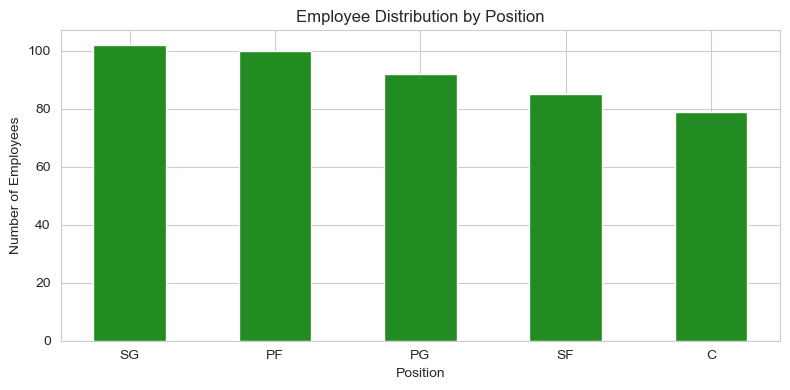

In [204]:
# Employee count by position
position_counts = df["Position"].value_counts()
print("Employee Distribution by Position:")
print(position_counts)


# Visualisation – Bar Chart: Employee Distribution by Position

plt.figure(figsize=(8,4))

plt.bar(position_counts.index,position_counts.values, color='ForestGreen', width=0.5)

plt.title("Employee Distribution by Position")
plt.xlabel("Position")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

3. Identify the predominant age group among employees.

Age Group
18-24    154
25-29    182
30-34     90
35-40     32
Name: count, dtype: int64

Predominant age group: 25-29
Employee Count: 182


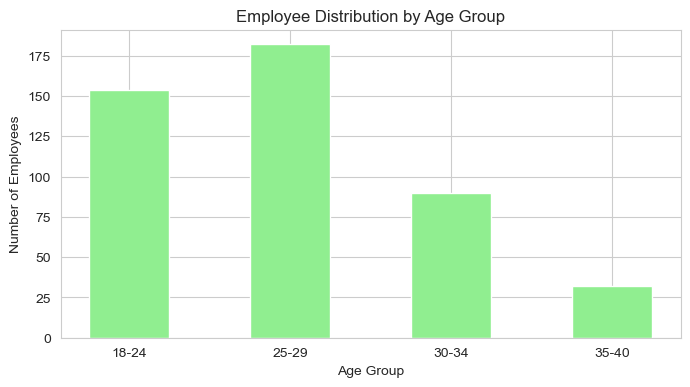

In [205]:
# Group ages into bins
bins = [18,24,29,34,40]
labels = ["18-24", "25-29", "30-34", "35-40"]
df["Age Group"] = pd.cut(df["Age"], bins=bins, labels=labels,  include_lowest=True)

age_group = df["Age Group"].value_counts().sort_index()
print(age_group)
print("\nPredominant age group:", age_group.idxmax())
print("Employee Count:", age_group.max())


# Visualisation – Bar Chart: Employee Distribution by Age Group
plt.figure(figsize=(8,4))
plt.bar(age_group.index.astype(str), age_group.values, color='Lightgreen', width=0.5)
plt.title("Employee Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Employees")
plt.show()


4. ● Discover which team and position have the highest salary expenditure. 


Highest spending team: Cleveland Cavaliers
Highest spending position: C


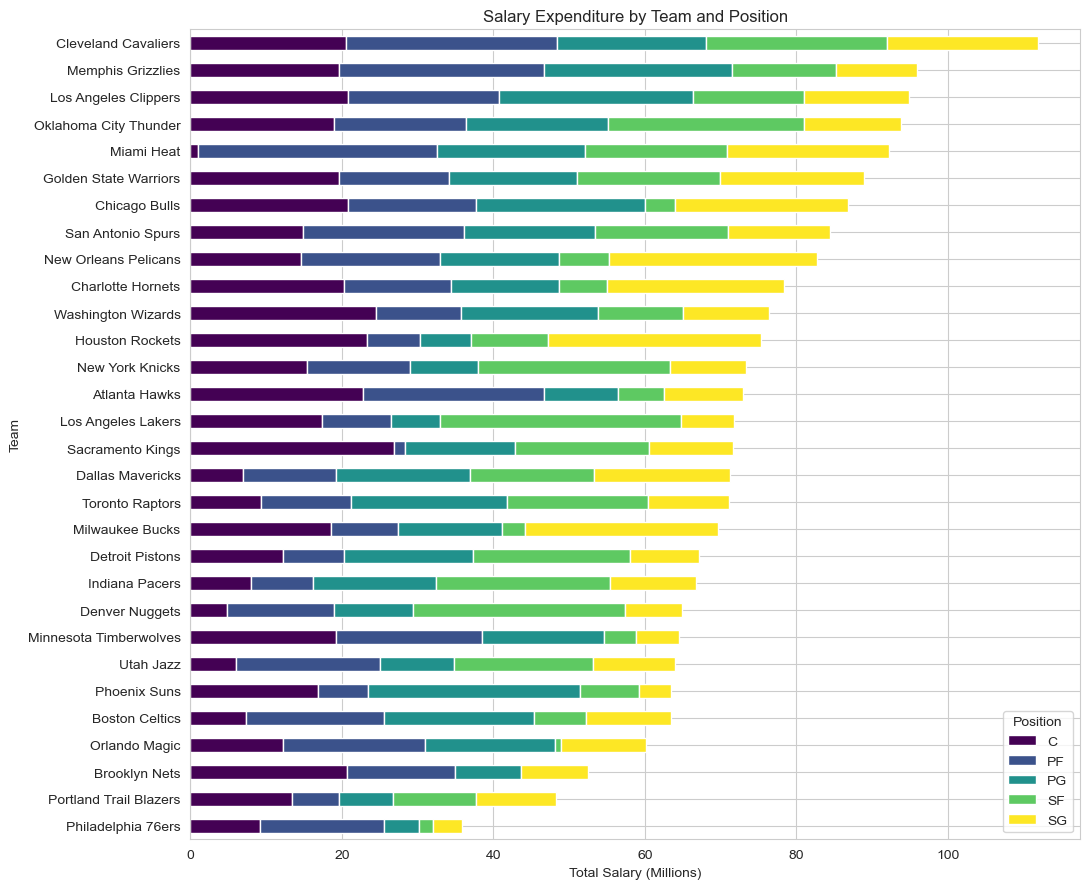

In [209]:
# Visualisation – Stacked horizontal bar chart: Salary Expenditure by Team and Position

# Create a pivot table
pivot = df.pivot_table(
    index="Team",
    columns="Position",
    values="Salary",
    aggfunc="sum"
)

# Convert salary into millions
pivot = pivot / 1e6

# Sort teams by total salary
pivot["Total"] = pivot.sum(axis=1)
pivot = pivot.sort_values(by="Total", ascending=True)

# Find highest spending team
print("Highest spending team:", pivot["Total"].idxmax())

# Remove Total column
pivot = pivot.drop(columns="Total")

# Find highest spending position
print("Highest spending position:", pivot.sum().idxmax())



# Create stacked horizontal bar chart
pivot.plot(kind="barh", stacked=True, figsize=(11, 9),
           colormap="viridis")

plt.title("Salary Expenditure by Team and Position")
plt.xlabel("Total Salary (Millions)")
plt.ylabel("Team")
plt.legend(title="Position")

plt.tight_layout()
plt.show()

5. ● Investigate if there's any correlation between age and salary, and represent it visually. 


Correlation between Age and Salary: 0.211


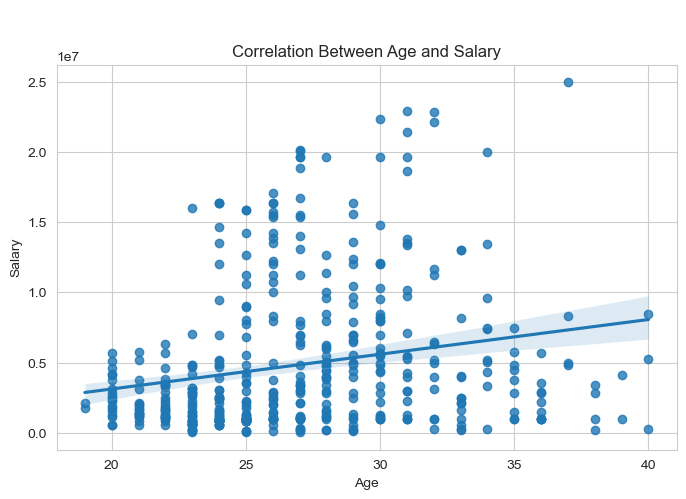

In [207]:
# Calculate correlation
correlation = df["Age"].corr(df["Salary"])

print("\nCorrelation between Age and Salary:", round(correlation,3))

# Visualisation – Scatter plot with regression line: Correlation Between Age and Salary
plt.figure(figsize=(8, 5))

sns.regplot(data=df, x="Age", y="Salary")

plt.title("\n\nCorrelation Between Age and Salary")
plt.xlabel("Age")
plt.ylabel("Salary")
plt.show()

### Data Story – ABC Company Employee Analysis
The ABC Company dataset consists of 458 employees across 30 teams. The analysis was carried out to understand employee distribution, position-wise representation, age groups, salary expenditure, and the relationship between age and salary.

The team-wise analysis shows that the workforce is fairly evenly distributed. The New Orleans Pelicans has the highest number of employees, with 19 (4.15%), followed by the Memphis Grizzlies with 18 (3.93%). The Minnesota Timberwolves and Orlando Magic have the lowest headcount, with 14 employees each (3.06%). Most teams have 15 employees (3.28%).

Regarding positions, SG form the largest group, with 102 employees (22.27%), while C have the lowest representation, with 79 employees (17.25%). The age analysis indicates that the workforce is relatively young, with the 25–29 age group being the largest, consisting of 182 employees (39.74%). Employees aged 18–29 account for approximately 73.36% of the total workforce.

The salary analysis reveals that the Cleveland Cavaliers have the highest total salary expenditure among all teams, while the C position accounts for the highest salary expenditure among the five positions. Finally, the correlation between age and salary is 0.211, indicating a weak positive relationship. This suggests that salary tends to increase slightly with age, but age alone does not strongly determine an employee's salary.

Conclusion: Overall, ABC Company has a relatively balanced distribution of employees across teams and positions, with a predominantly young workforce. Salary expenditure varies across teams and positions, while the weak positive correlation between age and salary suggests that other factors also influence employee compensation.